In [1]:
import pandas as pd
import numpy as np
from PIL import Image

manifest = pd.read_csv(
    "./dataset/spectrogram_images/manifest.csv"
)

# Keep only rows with confirmed labels
manifest = manifest.dropna(subset=["label"])
manifest = manifest[manifest["label"].astype(str).str.strip() != ""]

X = np.array([
    np.asarray(
        Image.open(path).convert("L"),
        dtype=np.float32
    ).flatten() / 255.0
    for path in manifest["image_path"]
])

y = manifest["label"].astype(str).to_numpy()

print("Feature matrix:", X.shape)
print("Labels:", y.shape)
print("Classes:", np.unique(y))

Feature matrix: (0,)
Labels: (0,)
Classes: []


In [2]:
import pandas as pd
from pathlib import Path

manifest_path = Path("./dataset/spectrogram_images/manifest.csv")
manifest = pd.read_csv(manifest_path)

print("Total manifest rows:", len(manifest))
print("\nColumns:", manifest.columns.tolist())
print("\nFirst five rows:")
display(manifest.head())

print("\nLabels:")
print(manifest["label"].value_counts(dropna=False))

print("\nExisting image files:", sum(
    Path(p).exists() for p in manifest["image_path"]
))

Total manifest rows: 750

Columns: ['image_path', 'audio_path', 'source_recording', 'label']

First five rows:


,image_path,audio_path,source_recording,label
0,dataset\spectrogram_images\A\event_001.png,dataset\detected\A\event_001.wav,A,NaN
1,dataset\spectrogram_images\A\event_002.png,dataset\detected\A\event_002.wav,A,NaN
2,dataset\spectrogram_images\A\event_003.png,dataset\detected\A\event_003.wav,A,NaN
3,dataset\spectrogram_images\A\event_004.png,dataset\detected\A\event_004.wav,A,NaN
4,dataset\spectrogram_images\A\event_005.png,dataset\detected\A\event_005.wav,A,NaN



Labels:
label
NaN    750
Name: count, dtype: int64

Existing image files: 750


In [3]:
import pandas as pd
from pathlib import Path

manifest_path = Path("./dataset/spectrogram_images/manifest.csv")

manifest = pd.read_csv(manifest_path)

# Assign each image the key named by its source folder
manifest["label"] = (
    manifest["source_recording"]
    .astype(str)
    .str.strip()
    .str.upper()
)

# Save the corrected manifest
manifest.to_csv(manifest_path, index=False)

print("Total images:", len(manifest))
print("\nImages per key:")
print(manifest["label"].value_counts().sort_index())

print("\nSample rows:")
display(manifest.head())

Total images: 750

Images per key:
label
A    30
B    28
C    22
D    33
E    30
F    17
G    31
H    27
I    32
J    32
K    27
L    35
M    22
N    28
O    30
P    29
Q    29
R    29
S    21
T    32
U    27
V    37
W    29
X    41
Y    24
Z    28
Name: count, dtype: int64

Sample rows:


,image_path,audio_path,source_recording,label
0,dataset\spectrogram_images\A\event_001.png,dataset\detected\A\event_001.wav,A,A
1,dataset\spectrogram_images\A\event_002.png,dataset\detected\A\event_002.wav,A,A
2,dataset\spectrogram_images\A\event_003.png,dataset\detected\A\event_003.wav,A,A
3,dataset\spectrogram_images\A\event_004.png,dataset\detected\A\event_004.wav,A,A
4,dataset\spectrogram_images\A\event_005.png,dataset\detected\A\event_005.wav,A,A


In [4]:
import numpy as np
from PIL import Image

X = np.stack([
    np.asarray(
        Image.open(path).convert("L").resize((128, 128)),
        dtype=np.float32
    ).flatten() / 255.0
    for path in manifest["image_path"]
])

y = manifest["label"].to_numpy()

print("Feature matrix X:", X.shape)
print("Labels y:", y.shape)
print("Classes:", np.unique(y))

Feature matrix X: (750, 16384)
Labels y: (750,)
Classes: ['A' 'B' 'C' 'D' 'E' 'F' 'G' 'H' 'I' 'J' 'K' 'L' 'M' 'N' 'O' 'P' 'Q' 'R'
 'S' 'T' 'U' 'V' 'W' 'X' 'Y' 'Z']


In [10]:
from sklearn.model_selection import train_test_split
import numpy as np
import pandas as pd

# Check class distribution first
print("Samples per key:")
print(pd.Series(y).value_counts().sort_index())

# 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("\nTraining samples per key:")
print(pd.Series(y_train).value_counts().sort_index())

print("\nTesting samples per key:")
print(pd.Series(y_test).value_counts().sort_index())

Samples per key:
A    30
B    28
C    22
D    33
E    30
F    17
G    31
H    27
I    32
J    32
K    27
L    35
M    22
N    28
O    30
P    29
Q    29
R    29
S    21
T    32
U    27
V    37
W    29
X    41
Y    24
Z    28
Name: count, dtype: int64

Training shape: (600, 16384)
Testing shape: (150, 16384)

Training samples per key:
A    24
B    22
C    18
D    26
E    24
F    14
G    25
H    22
I    26
J    25
K    22
L    28
M    18
N    22
O    24
P    23
Q    23
R    23
S    17
T    25
U    22
V    30
W    23
X    33
Y    19
Z    22
Name: count, dtype: int64

Testing samples per key:
A    6
B    6
C    4
D    7
E    6
F    3
G    6
H    5
I    6
J    7
K    5
L    7
M    4
N    6
O    6
P    6
Q    6
R    6
S    4
T    7
U    5
V    7
W    6
X    8
Y    5
Z    6
Name: count, dtype: int64


In [11]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Standardize using training data only
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Retain 95% of the variance
pca = PCA(
    n_components=0.95,
    random_state=42
)

X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print("Original features:", X_train.shape[1])
print("PCA features:", X_train_pca.shape[1])
print(
    f"Explained variance retained: "
    f"{pca.explained_variance_ratio_.sum():.2%}"
)

Original features: 16384
PCA features: 243
Explained variance retained: 95.01%


In [14]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report
import time

# Standardize features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# PCA retains 95% of training-set variance
pca = PCA(n_components=0.95, random_state=42)

X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print("Original features:", X_train.shape[1])
print("Features after PCA:", X_train_pca.shape[1])
print("Variance retained:",
      round(pca.explained_variance_ratio_.sum() * 100, 2), "%")

# Train ANN
ann = MLPClassifier(
    hidden_layer_sizes=(256, 128),
    activation="relu",
    solver="adam",
    alpha=0.001,
    batch_size=32,
    learning_rate_init=0.001,
    max_iter=200,
    early_stopping=True,
    validation_fraction=0.15,
    random_state=42
)

start = time.time()
ann.fit(X_train_pca, y_train)
training_time = time.time() - start

y_pred = ann.predict(X_test_pca)

print(f"\nTraining time: {training_time:.2f} seconds")
print(f"Test accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(classification_report(y_test, y_pred, zero_division=0))

Original features: 16384
Features after PCA: 243
Variance retained: 95.01 %

Training time: 1.36 seconds
Test accuracy: 0.7733
              precision    recall  f1-score   support

           A       0.80      0.67      0.73         6
           B       0.83      0.83      0.83         6
           C       0.60      0.75      0.67         4
           D       1.00      0.71      0.83         7
           E       0.80      0.67      0.73         6
           F       0.67      0.67      0.67         3
           G       0.83      0.83      0.83         6
           H       0.25      0.20      0.22         5
           I       1.00      1.00      1.00         6
           J       0.75      0.86      0.80         7
           K       0.33      0.40      0.36         5
           L       0.80      0.57      0.67         7
           M       0.80      1.00      0.89         4
           N       0.75      1.00      0.86         6
           O       0.71      0.83      0.77         6
        

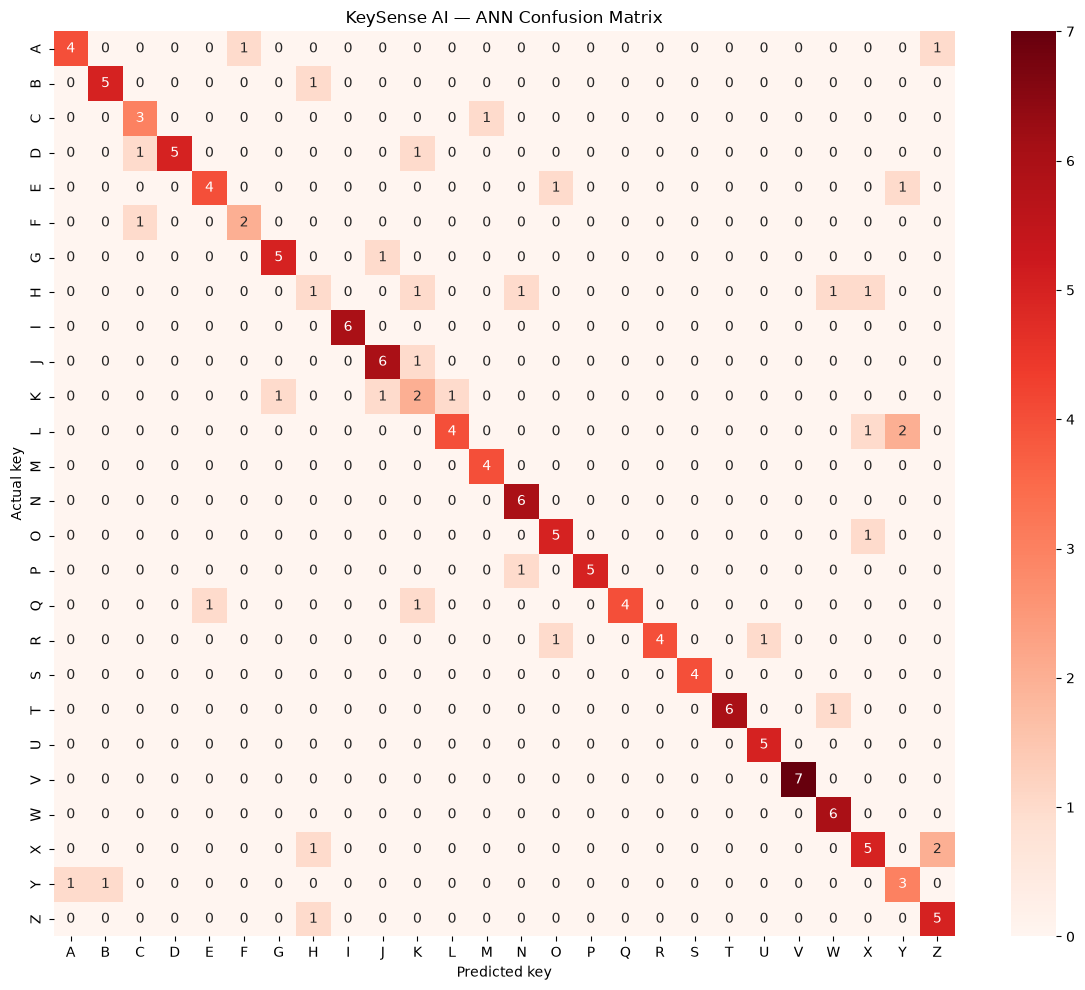

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

labels = sorted(np.unique(np.concatenate([y_test, y_pred])))

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=labels
)

plt.figure(figsize=(12, 10))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Reds",
    xticklabels=labels,
    yticklabels=labels
)

plt.xlabel("Predicted key")
plt.ylabel("Actual key")
plt.title("KeySense AI — ANN Confusion Matrix")
plt.tight_layout()
plt.show()

In [18]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    balanced_accuracy_score
)

print(f"Accuracy:          {accuracy_score(y_test, y_pred):.4f}")
print(f"Balanced accuracy: {balanced_accuracy_score(y_test, y_pred):.4f}")
print(f"Macro F1:          {f1_score(y_test, y_pred, average='macro'):.4f}")

print("\nPer-key performance:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy:          0.7733
Balanced accuracy: 0.7721
Macro F1:          0.7669

Per-key performance:
              precision    recall  f1-score   support

           A       0.80      0.67      0.73         6
           B       0.83      0.83      0.83         6
           C       0.60      0.75      0.67         4
           D       1.00      0.71      0.83         7
           E       0.80      0.67      0.73         6
           F       0.67      0.67      0.67         3
           G       0.83      0.83      0.83         6
           H       0.25      0.20      0.22         5
           I       1.00      1.00      1.00         6
           J       0.75      0.86      0.80         7
           K       0.33      0.40      0.36         5
           L       0.80      0.57      0.67         7
           M       0.80      1.00      0.89         4
           N       0.75      1.00      0.86         6
           O       0.71      0.83      0.77         6
           P       1.00      0.83  

In [19]:
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, f1_score
import time

ann_raw = MLPClassifier(
    hidden_layer_sizes=(256, 128),
    max_iter=200,
    early_stopping=True,
    random_state=42
)

start = time.time()
ann_raw.fit(X_train, y_train)
raw_time = time.time() - start

raw_pred = ann_raw.predict(X_test)

print("ANN without PCA")
print(f"Accuracy: {accuracy_score(y_test, raw_pred):.4f}")
print(f"Macro F1: {f1_score(y_test, raw_pred, average='macro'):.4f}")
print(f"Training time: {raw_time:.2f} seconds")

print("\nANN with PCA")
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(f"Macro F1: {f1_score(y_test, y_pred, average='macro'):.4f}")

ANN without PCA
Accuracy: 0.8400
Macro F1: 0.8364
Training time: 10.33 seconds

ANN with PCA
Accuracy: 0.7733
Macro F1: 0.7669


In [21]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

# Load labeled manifest
manifest = pd.read_csv("./dataset/spectrogram_images/manifest.csv")
manifest = manifest.dropna(subset=["label", "image_path"]).copy()

manifest["label"] = manifest["label"].astype(str).str.strip().str.upper()
manifest = manifest[manifest["label"] != ""]

# Load grayscale spectrograms
images = []

for path in manifest["image_path"]:
    with Image.open(path) as img:
        img = img.convert("L").resize((128, 128))
        images.append(np.asarray(img, dtype=np.float32) / 255.0)

X_cnn = np.array(images)[..., np.newaxis]

encoder = LabelEncoder()
y_cnn = encoder.fit_transform(manifest["label"])

print("Images:", X_cnn.shape)
print("Labels:", y_cnn.shape)
print("Classes:", list(encoder.classes_))

Images: (750, 128, 128, 1)
Labels: (750,)
Classes: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z']


In [22]:

indices = np.arange(len(y_cnn))

train_idx, test_idx = train_test_split(
    indices,
    test_size=0.20,
    random_state=42,
    stratify=y_cnn
)

X_train_cnn = X_cnn[train_idx]
X_test_cnn = X_cnn[test_idx]

y_train_cnn = y_cnn[train_idx]
y_test_cnn = y_cnn[test_idx]

print("Training images:", X_train_cnn.shape)
print("Testing images:", X_test_cnn.shape)

Training images: (600, 128, 128, 1)
Testing images: (150, 128, 128, 1)


In [23]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input,
    Conv2D,
    MaxPooling2D,
    BatchNormalization,
    Flatten,
    Dense,
    Dropout
)

num_classes = len(encoder.classes_)

cnn = Sequential([
    Input(shape=(128, 128, 1)),

    Conv2D(32, (3, 3), activation="relu", padding="same"),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation="relu", padding="same"),
    BatchNormalization(),
    MaxPooling2D((2, 2)),

    Conv2D(128, (3, 3), activation="relu", padding="same"),
    MaxPooling2D((2, 2)),

    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.4),
    Dense(num_classes, activation="softmax")
])

cnn.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

cnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 26)             │         3,354 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,290,714 (16.37 MB)

 Trainable params: 4,290,586 (16.37 MB)

 Non-trainable params: 128 (512.00 B)

In [ ]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input,
    Conv2D,
    MaxPooling2D,
    BatchNormalization,
    Flatten,
    Dense,
    Dropout
)

num_classes = len(encoder.classes_)

cnn = Sequential([
    Input(shape=(128, 128, 1)),

    Conv2D(32, (3, 3), activation="relu", padding="same"),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation="relu", padding="same"),
    BatchNormalization(),
    MaxPooling2D((2, 2)),

    Conv2D(128, (3, 3), activation="relu", padding="same"),
    MaxPooling2D((2, 2)),

    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.4),
    Dense(num_classes, activation="softmax")
])

cnn.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

cnn.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 128, 128, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 26)             │         3,354 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,290,714 (16.37 MB)

 Trainable params: 4,290,586 (16.37 MB)

 Non-trainable params: 128 (512.00 B)

In [25]:
from tensorflow.keras.callbacks import EarlyStopping
import time

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

start = time.time()

history = cnn.fit(
    X_train_cnn,
    y_train_cnn,
    epochs=40,
    batch_size=32,
    validation_split=0.15,
    callbacks=[early_stop],
    verbose=1
)

cnn_training_time = time.time() - start

print(f"\nTraining time: {cnn_training_time:.2f} seconds")

Epoch 1/40
16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 137ms/step - accuracy: 0.0608 - loss: 4.1997 - val_accuracy: 0.0111 - val_loss: 3.2580
Epoch 2/40
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 117ms/step - accuracy: 0.0961 - loss: 3.1550 - val_accuracy: 0.0667 - val_loss: 3.2579
Epoch 3/40
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 118ms/step - accuracy: 0.1490 - loss: 3.0098 - val_accuracy: 0.0667 - val_loss: 3.2495
Epoch 4/40
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 132ms/step - accuracy: 0.1608 - loss: 2.8515 - val_accuracy: 0.0667 - val_loss: 3.2408
Epoch 5/40
16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 164ms/step - accuracy: 0.1980 - loss: 2.6305 - val_accuracy: 0.0667 - val_loss: 3.2280
Epoch 6/40
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 130ms/step - accuracy: 0.2843 - loss: 2.3241 - val_accuracy: 0.2333 - val_loss: 3.2234
Epoch 7/40
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 123ms/step - accuracy: 0.3843 - loss: 2.0437 - val_accuracy: 0.3333 - val_loss: 3.2006
Epoch 8/40
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 132ms/step - accuracy: 0.4118 - loss: 1.7925 - val_accuracy: 0.

In [26]:
probabilities = cnn.predict(X_test_cnn, verbose=0)
y_pred_cnn = np.argmax(probabilities, axis=1)

print(f"CNN accuracy: {accuracy_score(y_test_cnn, y_pred_cnn):.4f}")
print(
    f"CNN macro F1: "
    f"{f1_score(y_test_cnn, y_pred_cnn, average='macro'):.4f}"
)

print("\nClassification report:")
print(classification_report(
    y_test_cnn,
    y_pred_cnn,
    labels=np.arange(num_classes),
    target_names=encoder.classes_,
    zero_division=0
))

CNN accuracy: 0.8600
CNN macro F1: 0.8544

Classification report:
              precision    recall  f1-score   support

           A       1.00      0.83      0.91         6
           B       1.00      1.00      1.00         6
           C       1.00      0.75      0.86         4
           D       1.00      0.86      0.92         7
           E       0.83      0.83      0.83         6
           F       1.00      1.00      1.00         3
           G       0.71      0.83      0.77         6
           H       0.50      0.40      0.44         5
           I       0.86      1.00      0.92         6
           J       0.88      1.00      0.93         7
           K       0.67      0.80      0.73         5
           L       0.80      0.57      0.67         7
           M       0.80      1.00      0.89         4
           N       1.00      1.00      1.00         6
           O       1.00      0.83      0.91         6
           P       0.83      0.83      0.83         6
           Q   

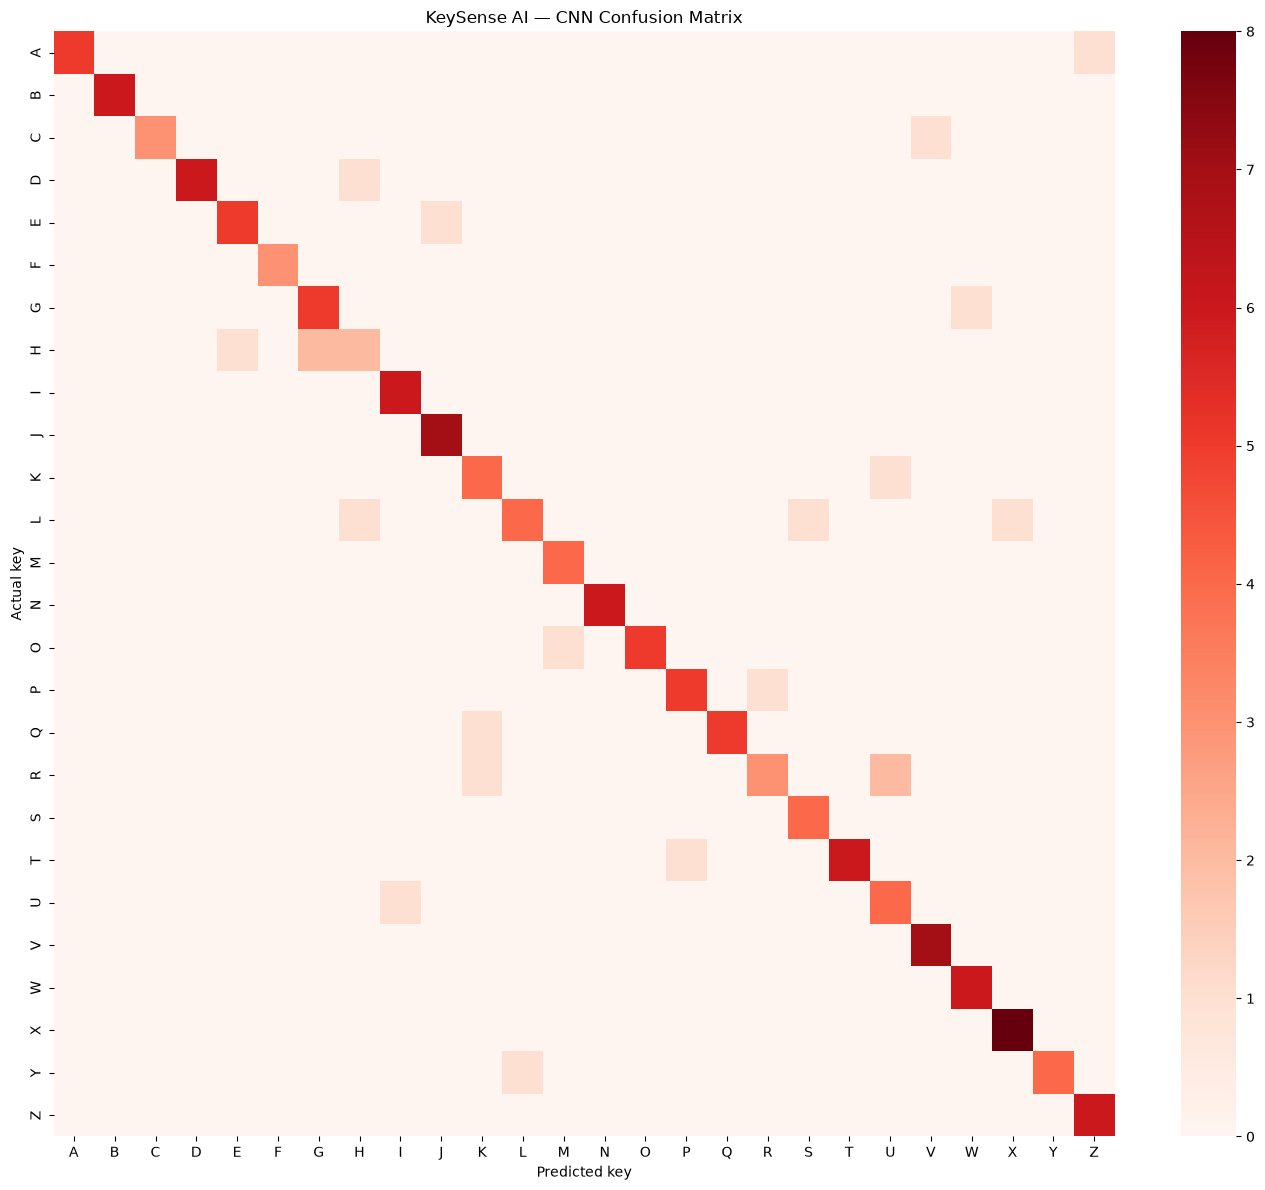

In [27]:
cm = confusion_matrix(
    y_test_cnn,
    y_pred_cnn,
    labels=np.arange(num_classes)
)

plt.figure(figsize=(14, 12))
import seaborn as sns

sns.heatmap(
    cm,
    cmap="Reds",
    xticklabels=encoder.classes_,
    yticklabels=encoder.classes_
)

plt.title("KeySense AI — CNN Confusion Matrix")
plt.xlabel("Predicted key")
plt.ylabel("Actual key")
plt.tight_layout()
plt.show()

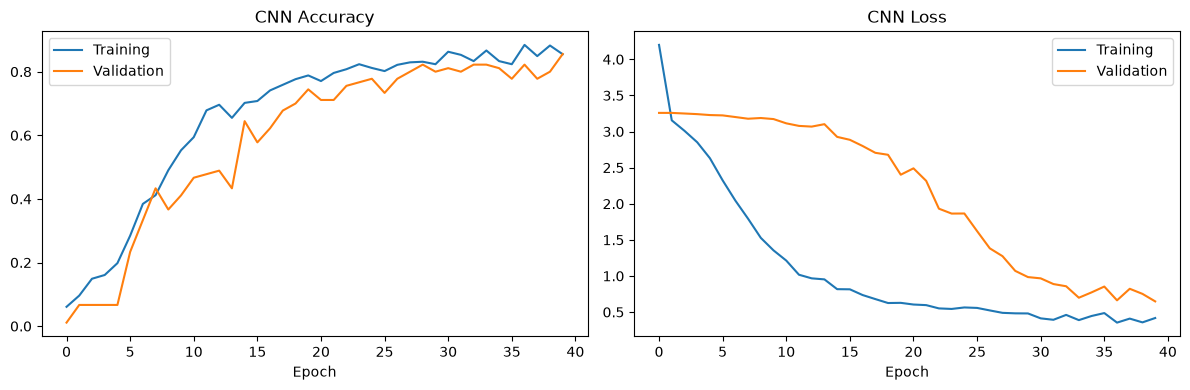

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history["accuracy"], label="Training")
axes[0].plot(history.history["val_accuracy"], label="Validation")
axes[0].set_title("CNN Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history.history["loss"], label="Training")
axes[1].plot(history.history["val_loss"], label="Validation")
axes[1].set_title("CNN Loss")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

In [31]:
[name for name in globals()
 if "encoder" in name.lower() or name == "le"]

['LabelEncoder', 'encoder']

In [32]:
from sklearn.metrics import accuracy_score, f1_score, classification_report

cnn_accuracy = accuracy_score(y_test_cnn, y_pred_cnn)
cnn_macro_f1 = f1_score(y_test_cnn, y_pred_cnn, average="macro")

print(f"CNN Test Accuracy: {cnn_accuracy:.4f}")
print(f"CNN Macro F1:      {cnn_macro_f1:.4f}")

print(classification_report(
    y_test_cnn,
    y_pred_cnn,
    labels=np.arange(len(encoder.classes_)),
    target_names=encoder.classes_,
    zero_division=0
))

CNN Test Accuracy: 0.8600
CNN Macro F1:      0.8544
              precision    recall  f1-score   support

           A       1.00      0.83      0.91         6
           B       1.00      1.00      1.00         6
           C       1.00      0.75      0.86         4
           D       1.00      0.86      0.92         7
           E       0.83      0.83      0.83         6
           F       1.00      1.00      1.00         3
           G       0.71      0.83      0.77         6
           H       0.50      0.40      0.44         5
           I       0.86      1.00      0.92         6
           J       0.88      1.00      0.93         7
           K       0.67      0.80      0.73         5
           L       0.80      0.57      0.67         7
           M       0.80      1.00      0.89         4
           N       1.00      1.00      1.00         6
           O       1.00      0.83      0.91         6
           P       0.83      0.83      0.83         6
           Q       1.00      